# Intersection Heading Matching

Zusatznotebook zum Filtern der bereits raeumlich gefilterten Cityscapes-Bilder nach Blickrichtung.

Wir nutzen die vier vorhandenen CSVs aus `output/intersection_filtered` (Fine/Coarse x 3/4-Strassen) und kombinieren sie mit den Cityscapes Vehicle-Metadaten (`gpsHeading`). Bilder werden zusaetzlich herausgefiltert, wenn ihre Blickrichtung innerhalb einer Toleranz zum Intersection-Mittelpunkt liegt.

**Pfadinventar**
- Filter-Inputs: `output/intersection_filtered/*.csv`
- Intersection-Referenzen: `output/cityscapes_intersections_3_strassen.csv`, `output/cityscapes_intersections_4_strassen.csv`
- Vehicle-Metadaten (Heading):
  - `data/city_scapes/vehicle_trainextra/vehicle/train_extra/<city>/<image_id>_vehicle.json`
  - `data/city_scapes/vehicle_trainvaltest/vehicle/{train,val,test}/<city>/<image_id>_vehicle.json`
- Output: `output/intersection_heading_filtered/*`


In [83]:
import json
import math
from pathlib import Path
import pandas as pd

base_dir = Path(r'C:/Users/kamme/OneDrive/Desktop/uni/Master/DIS/gitlabrepo/dis_1b_wise2025_26')
filtered_dir = base_dir / 'output' / 'intersection_filtered'
heading_output_dir = base_dir / 'output' / 'intersection_heading_filtered'
heading_output_dir.mkdir(parents=True, exist_ok=True)

intersections_files = {
    '4': base_dir / 'output' / 'cityscapes_intersections_4_strassen.csv',
    '3': base_dir / 'output' / 'cityscapes_intersections_3_strassen.csv',
}
vehicle_root_trainextra = base_dir / 'data' / 'city_scapes' / 'vehicle_trainextra' / 'vehicle' / 'train_extra'
vehicle_root_trainval = base_dir / 'data' / 'city_scapes' / 'vehicle_trainvaltest' / 'vehicle'



Konfiguration & Pfade: setzt Basisverzeichnisse, Pfade zu den vier bereits räumlich gefilterten CSVs, legt den Ausgabeordner `output/intersection_heading_filtered` an und verweist auf die Intersection-Referenzdateien (3- und 4-Straßen-Definition).

In [84]:
def compute_bearing_deg(lat1, lon1, lat2, lon2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dlon = math.radians(lon2 - lon1)
    x = math.sin(dlon) * math.cos(phi2)
    y = math.cos(phi1) * math.sin(phi2) - math.sin(phi1) * math.cos(phi2) * math.cos(dlon)
    brng = math.degrees(math.atan2(x, y))
    return (brng + 360) % 360

def angular_diff_deg(a, b):
    d = abs(a - b) % 360
    return d if d <= 180 else 360 - d

def load_heading(city, split, image_id):
    if split == 'train_extra':
        path = vehicle_root_trainextra / city / f"{image_id}_vehicle.json"
    else:
        path = vehicle_root_trainval / split / city / f"{image_id}_vehicle.json"
    if not path.exists():
        return None
    try:
        data = json.loads(path.read_text())
        return float(data.get('gpsHeading')) if 'gpsHeading' in data else None
    except Exception:
        return None



Hilfsfunktionen: berechnet die Peilung zum Intersection-Mittelpunkt, den kleinsten Winkelunterschied zwischen Blickrichtung und Ziel sowie lädt `gpsHeading` aus den Vehicle-Metadaten (train_extra bzw. train/val/test).

In [85]:
# Intersection-Lookups vorbereiten (intersection_id -> Koordinaten, keyed by city+id)
intersection_lookup = {}
for key, path in intersections_files.items():
    df_int = pd.read_csv(path)
    df_int['intersection_id'] = df_int['intersection_id'].astype(int)
    df_int = df_int.set_index(['city', 'intersection_id'])[['latitude', 'longitude']]
    intersection_lookup[key] = df_int
    print(f"{key}-Strassen CSV geladen: {len(df_int):,} Zeilen")


4-Strassen CSV geladen: 36,260 Zeilen
3-Strassen CSV geladen: 188,437 Zeilen


Intersection-Lookup: liest die 3er- und 4er-Intersection-CSV und legt ein Mapping `intersection_id -> (lat, lon)` an, damit später für jede Bildzeile der Zielpunkt bekannt ist.

In [86]:
variants = [
    {'label': 'coarse_4', 'images': filtered_dir / 'coarse_images_within_intersections_4.csv', 'intersection_key': '4'},
    {'label': 'coarse_3', 'images': filtered_dir / 'coarse_images_within_intersections_3.csv', 'intersection_key': '3'},
    {'label': 'fine_4',   'images': filtered_dir / 'fine_images_within_intersections_4.csv',   'intersection_key': '4'},
    {'label': 'fine_3',   'images': filtered_dir / 'fine_images_within_intersections_3.csv',   'intersection_key': '3'},
]

# Akzeptierter Blickkegel (Toleranz +/- in Grad) fuer das Heading-Matching
heading_tolerance_deg = 90  # aktuell +-90 Grad um die Zielrichtung

def enrich_with_heading(df, lookup_key):
    lookup = intersection_lookup[lookup_key]
    def _calc(row):
        # intersection_id kann als float aus CSV kommen -> in int casten fuer Lookup
        try:
            inter_id = int(float(row.intersection_id))
        except Exception:
            return pd.Series({'heading_deg': pd.NA, 'bearing_to_intersection_deg': pd.NA, 'heading_diff_deg': pd.NA})
        heading = load_heading(row.city, row.split, row.image_id)
        if heading is None:
            return pd.Series({'heading_deg': pd.NA, 'bearing_to_intersection_deg': pd.NA, 'heading_diff_deg': pd.NA})
        try:
            lat_img = float(row.latitude)
            lon_img = float(row.longitude)
        except Exception:
            return pd.Series({'heading_deg': heading, 'bearing_to_intersection_deg': pd.NA, 'heading_diff_deg': pd.NA})
        try:
            lat_i, lon_i = lookup.loc[(row.city, inter_id), ['latitude', 'longitude']]
            lat_i = float(lat_i)
            lon_i = float(lon_i)
        except Exception:
            return pd.Series({'heading_deg': heading, 'bearing_to_intersection_deg': pd.NA, 'heading_diff_deg': pd.NA})
        bearing = compute_bearing_deg(lat_img, lon_img, lat_i, lon_i)
        diff = angular_diff_deg(heading, bearing)
        return pd.Series({'heading_deg': heading, 'bearing_to_intersection_deg': bearing, 'heading_diff_deg': diff})
    return df.join(df.apply(_calc, axis=1))


Varianten & Heading-Join: definiert die vier Datensätze (coarse/fine × 3/4), setzt den Toleranzwinkel und reichert jede Bildzeile um Heading, Bearing und Winkelabweichung an.

In [87]:
summary = []
for variant in variants:
    df_images = pd.read_csv(variant['images'])
    enriched = enrich_with_heading(df_images, variant['intersection_key'])
    filtered = enriched[(enriched['heading_diff_deg'].notna()) & (enriched['heading_diff_deg'] <= heading_tolerance_deg)].copy()

    out_path = heading_output_dir / f"{variant['label']}_heading_filtered.csv"
    filtered.to_csv(out_path, index=False)

    summary.append({
        'label': variant['label'],
        'input_rows': len(df_images),
        'with_heading': enriched['heading_deg'].notna().sum(),
        'kept_heading_tol': len(filtered),
        'output_path': out_path,
    })

summary_df = pd.DataFrame(summary)
summary_df

print('Bilder pro Output-CSV (nach Heading-Filter):')
print(summary_df[['label', 'kept_heading_tol', 'output_path']])
print('Vergleich Input -> Output (vor/nach Heading-Filter):')
for row in summary: print(f"{row['label']}: {row['input_rows']} -> {row['kept_heading_tol']}")


Bilder pro Output-CSV (nach Heading-Filter):
      label  kept_heading_tol  \
0  coarse_4               934   
1  coarse_3              3032   
2    fine_4               300   
3    fine_3               845   

                                         output_path  
0  C:\Users\kamme\OneDrive\Desktop\uni\Master\DIS...  
1  C:\Users\kamme\OneDrive\Desktop\uni\Master\DIS...  
2  C:\Users\kamme\OneDrive\Desktop\uni\Master\DIS...  
3  C:\Users\kamme\OneDrive\Desktop\uni\Master\DIS...  
Vergleich Input -> Output (vor/nach Heading-Filter):
coarse_4: 1912 -> 934
coarse_3: 6269 -> 3032
fine_4: 576 -> 300
fine_3: 1655 -> 845


Output & Zusammenfassung: schreibt pro Variante eine heading-gefilterte CSV nach `output/intersection_heading_filtered` und fasst Eingangszeilen, verfügbare Headings und verbleibende Treffer in einer Übersichtstabelle zusammen.

## Beispiel-Visualisierung des Heading-Filters
Anhand eines Beispiel-Bildes (standard: coarse_4) visualisieren wir Kameraposition, Intersection-Zielpunkt, die Verbindungslinie sowie Heading/Bearing/Winkelabweichung, um den Filter nachvollziehbar zu machen.


In [88]:
import folium
import math
import numpy as np

example_label = 'fine_4'  # bei Bedarf 'coarse_3', 'fine_4', 'fine_3' setzen
example_variant = next(v for v in variants if v['label'] == example_label)
df_example = pd.read_csv(example_variant['images'])
enriched_example = enrich_with_heading(df_example, example_variant['intersection_key'])
sample = enriched_example[enriched_example['heading_deg'].notna()].iloc[0]

heading_deg = float(sample.heading_deg)
bearing_deg = float(sample.bearing_to_intersection_deg)
diff_deg = float(sample.heading_diff_deg)

# Kleine Hilfsfunktion: Heading + Distanz -> approx. Offset in Lat/Lon (nur Visualisierung)
def project_point(lat, lon, bearing_deg, distance_m=80):
    R = 6378137.0
    rad = math.radians(bearing_deg)
    d_lat = (distance_m * math.cos(rad)) / R
    d_lon = (distance_m * math.sin(rad)) / (R * math.cos(math.radians(lat)))
    return lat + math.degrees(d_lat), lon + math.degrees(d_lon)

cam_point = (float(sample.latitude), float(sample.longitude))
try:
    lat_i, lon_i = intersection_lookup[example_variant['intersection_key']].loc[(sample.city, int(float(sample.intersection_id))), ['latitude','longitude']]
    int_point = (float(lat_i), float(lon_i))
except Exception:
    int_point = cam_point

# Kegel als Wedge (Bogen mit mehreren Punkten)
angles = np.linspace(heading_deg - heading_tolerance_deg, heading_deg + heading_tolerance_deg, 60)
wedge_pts = [project_point(cam_point[0], cam_point[1], ang, distance_m=80) for ang in angles]
wedge_polygon = [cam_point] + wedge_pts + [cam_point]

map_center = [(cam_point[0] + int_point[0]) / 2, (cam_point[1] + int_point[1]) / 2]
m = folium.Map(location=map_center, zoom_start=16, tiles='cartodbpositron')
folium.CircleMarker(location=cam_point, radius=5, color='blue', fill=True, fill_opacity=0.8, popup='Kamera').add_to(m)
folium.CircleMarker(location=int_point, radius=5, color='orange', fill=True, fill_opacity=0.8, popup='Intersection').add_to(m)
folium.PolyLine(locations=[cam_point, int_point], color='green', weight=2, opacity=0.8, popup='Zielrichtung').add_to(m)
# Kegel visualisieren (Wedge)
folium.Polygon(locations=wedge_polygon, color='skyblue', fill=True, fill_opacity=0.15, weight=1, dash_array='5,5').add_to(m)

popup_text = f"Heading: {heading_deg:.1f}°\nBearing (zum Ziel): {bearing_deg:.1f}°\nDiff: {diff_deg:.1f}°\nToleranz: ±{heading_tolerance_deg}°"
folium.Marker(location=cam_point, popup=popup_text, icon=folium.Icon(color='blue', icon='info-sign')).add_to(m)
m


### Heading-Kegel (polar)
Das folgende Diagramm zeigt Heading (blau), Bearing zur Intersection (orange) und den zugelassenen Toleranzkegel (blau schattiert) in einer Polardarstellung.


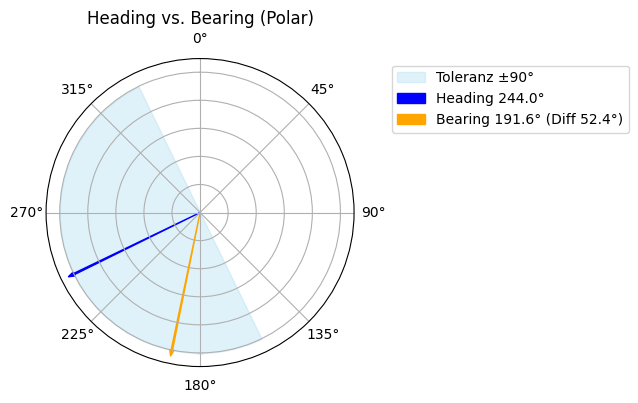

In [89]:
import matplotlib.pyplot as plt
import numpy as np
import math
cone_example_label = 'fine_4'  # Beispiel fuer die Polar-Visualisierung
cone_variant = next(v for v in variants if v['label'] == cone_example_label)
cone_df = pd.read_csv(cone_variant['images'])
cone_enriched = enrich_with_heading(cone_df, cone_variant['intersection_key'])
cone_sample = cone_enriched[cone_enriched['heading_deg'].notna()].iloc[0]

heading = float(cone_sample.heading_deg)
bearing = float(cone_sample.bearing_to_intersection_deg)
diff = float(cone_sample.heading_diff_deg)
tol = heading_tolerance_deg

fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(6, 4))
angles = np.linspace(math.radians(heading - tol), math.radians(heading + tol), 60)
ax.fill_between(angles, 0, 1, color="skyblue", alpha=0.25, label=f"Toleranz ±{tol}°")
ax.arrow(math.radians(heading), 0, 0, 1, color="blue", width=0.01, label=f"Heading {heading:.1f}°")
ax.arrow(math.radians(bearing), 0, 0, 1, color="orange", width=0.01, label=f"Bearing {bearing:.1f}° (Diff {diff:.1f}°)")
ax.set_yticklabels([])
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_title("Heading vs. Bearing (Polar)")
ax.legend(loc="upper left", bbox_to_anchor=(1.1, 1))
plt.show()
